# PRCP-1000 – Portuguese Bank Marketing

**Domain:** Finance / Banking
**Data:** direct phone-call marketing campaigns of a Portuguese bank (May 2008 – Nov 2010), `bank-additional-full.csv`.
**Goal:** predict which customers will subscribe to a term deposit, and advise the marketing team.

**Contents**
1. Task 1 – Data Analysis Report
2. Task 2 – Predictive Model
3. Model Comparison Report
4. Report on Challenges Faced
5. Task 3 – Suggestions to the Marketing Team
6. Conclusion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

## 1. Task 1 – Data Analysis Report
### 1.1 Load the data

In [2]:
df = pd.read_csv("data/bank-additional-full.csv", sep=";")
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.2 Structure and summary statistics

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


### 1.3 Data quality – nulls, duplicates and 'unknown' values

In [5]:
print("Null values   :", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
unknown_counts = (df == "unknown").sum()
unknown_counts[unknown_counts > 0].sort_values(ascending=False)

Null values   : 0
Duplicate rows: 12


default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

### 1.4 Target variable

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


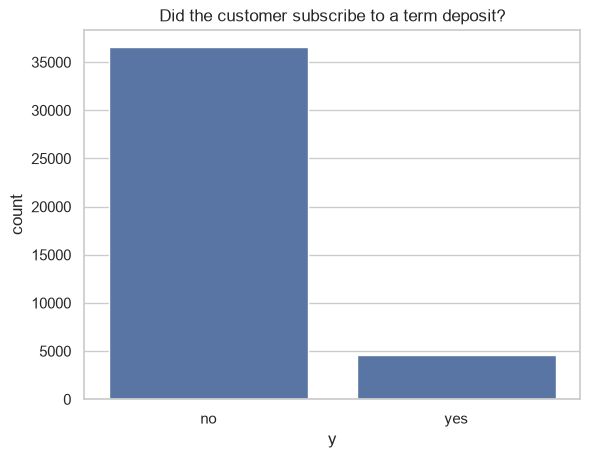

In [6]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))
sns.countplot(x="y", data=df)
plt.title("Did the customer subscribe to a term deposit?")
plt.show()

### 1.5 Distribution of numeric features

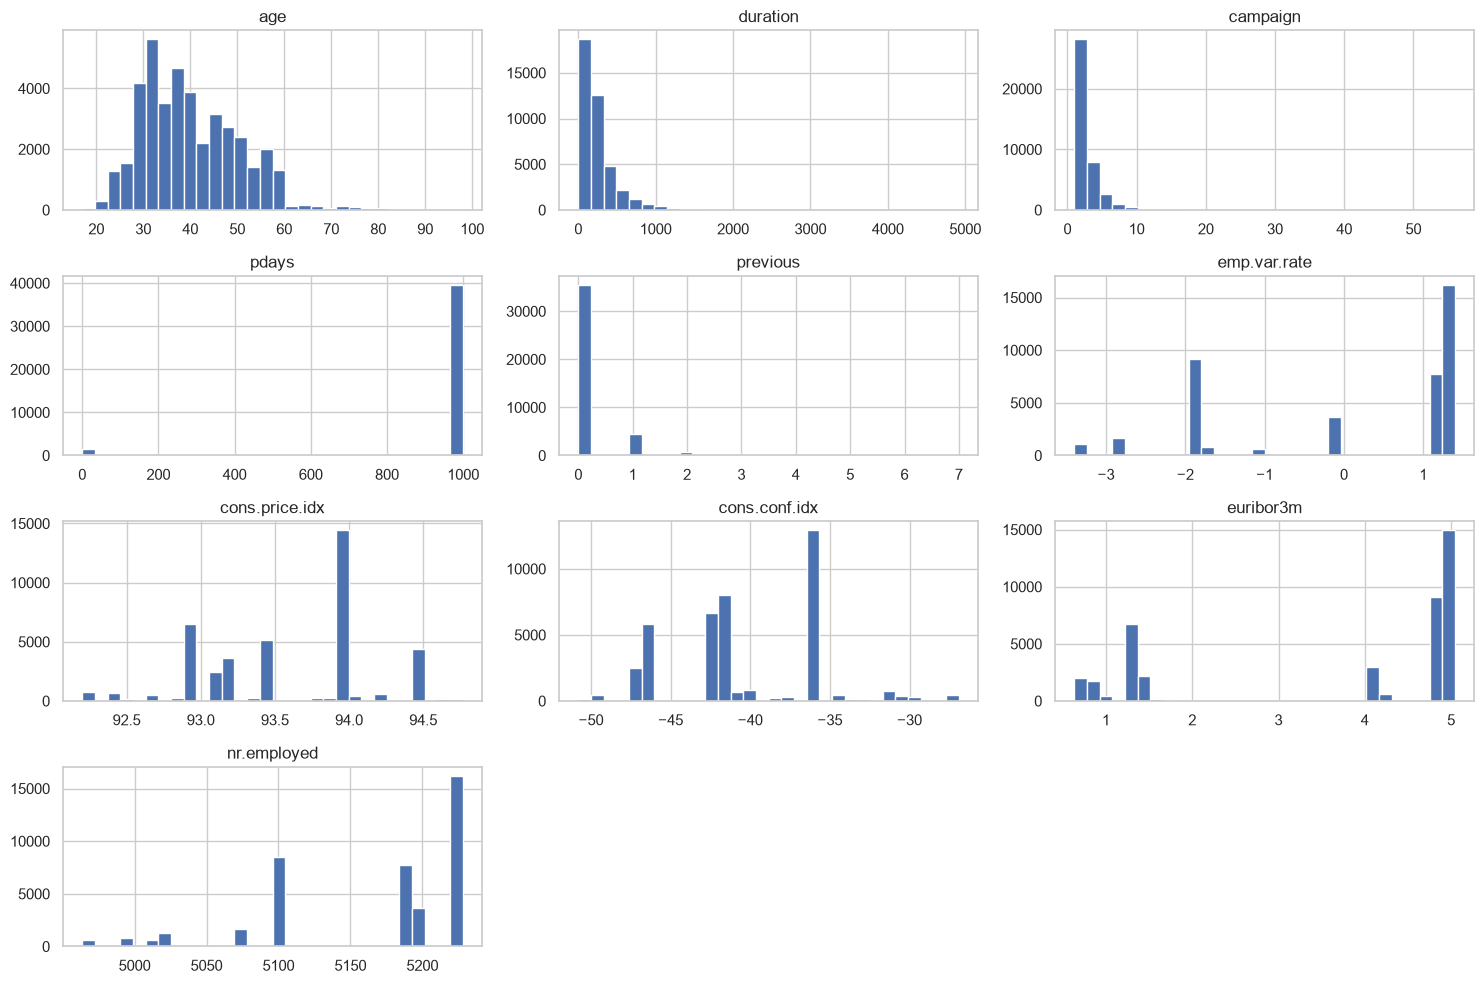

In [7]:
num_cols = df.select_dtypes(include="number").columns.tolist()
df[num_cols].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

### 1.6 Subscription rate by categorical feature

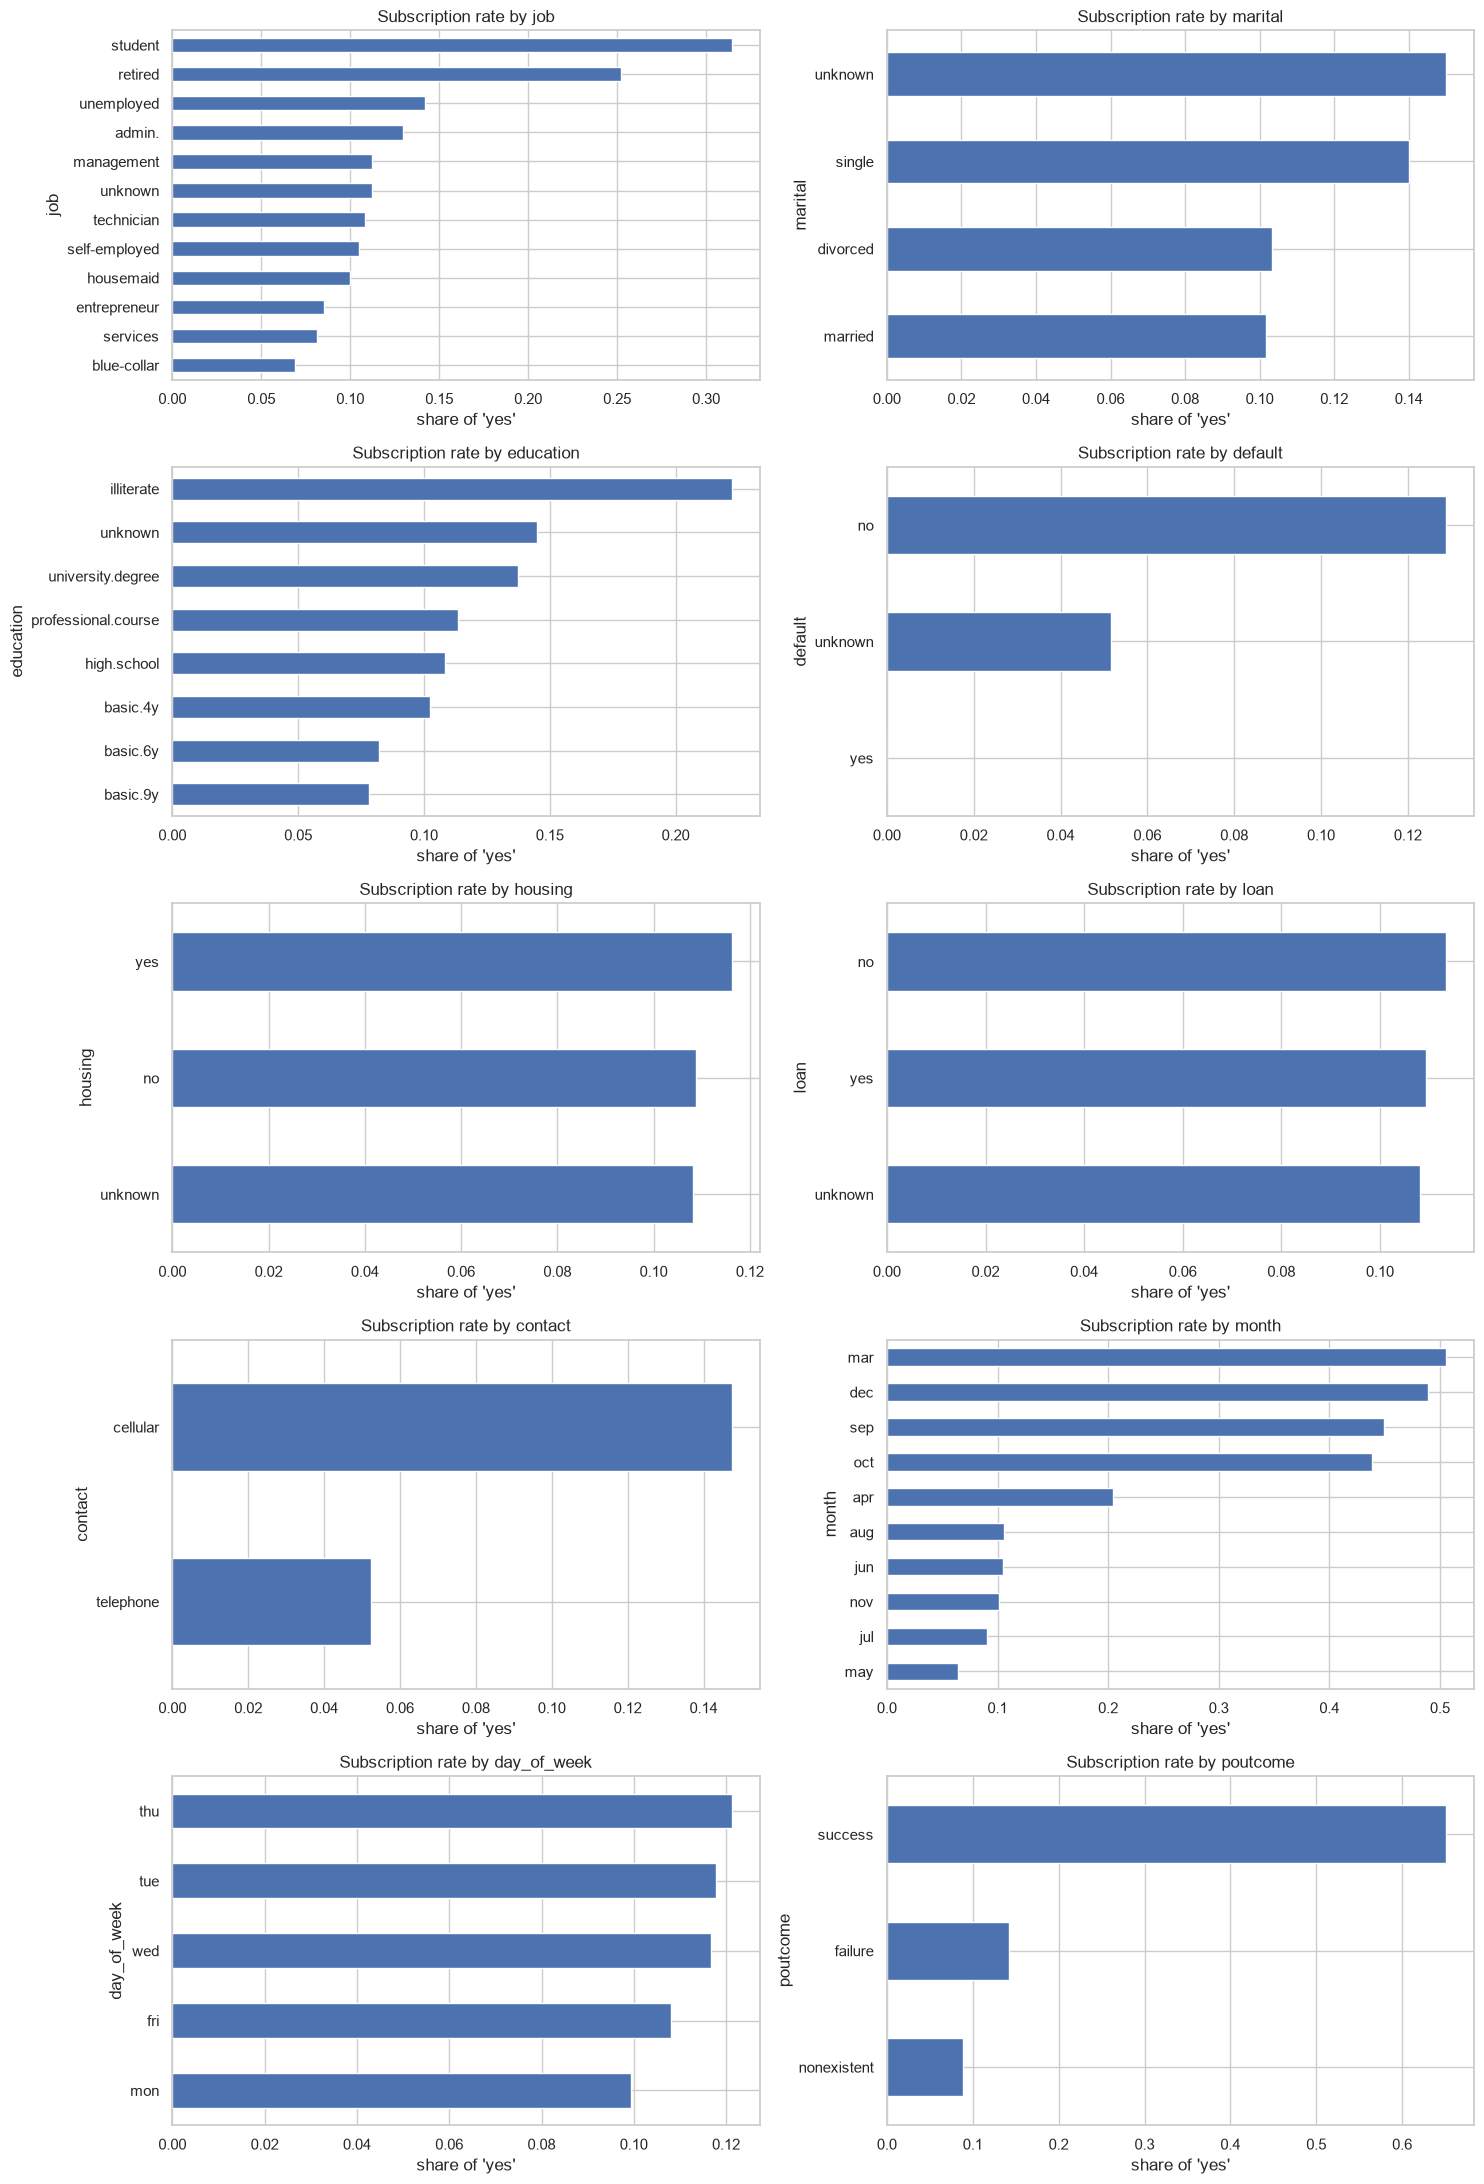

In [8]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()

fig, axes = plt.subplots(5, 2, figsize=(15, 22))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    rate.plot(kind="barh", ax=ax)
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("share of 'yes'")
plt.tight_layout()
plt.show()

Number of calls per month vs. subscription rate:

In [9]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_stats = df.groupby("month").agg(calls=("y", "size"),
                                      rate=("y", lambda s: (s == "yes").mean()))
month_stats.reindex(month_order).round(3)

,calls,rate
month,,
mar,546,0.505
apr,2632,0.205
may,13769,0.064
jun,5318,0.105
jul,7174,0.090
aug,6178,0.106
sep,570,0.449
oct,718,0.439
nov,4101,0.101


Subscription rate by number of calls in this campaign:

In [10]:
calls = df["campaign"].clip(upper=10)
df.groupby(calls)["y"].apply(lambda s: (s == "yes").mean()).round(3).rename("rate (10 = 10+ calls)")

campaign
1     0.130
2     0.115
3     0.107
4     0.094
5     0.075
6     0.077
7     0.060
8     0.042
9     0.060
10    0.036
Name: rate (10 = 10+ calls), dtype: float64

### 1.7 Numeric features vs. target and correlation

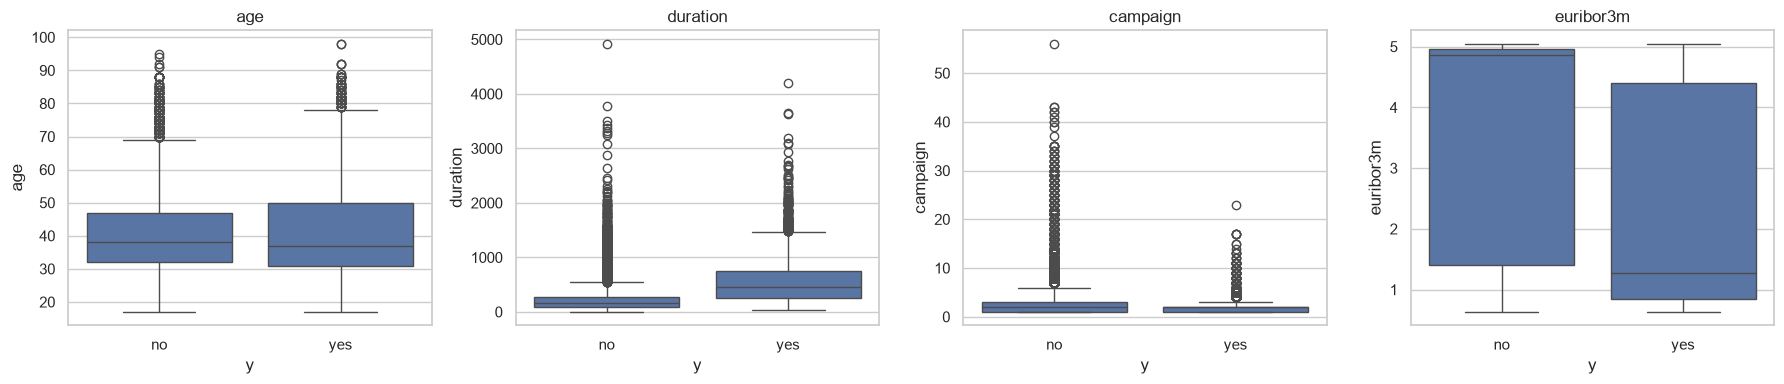

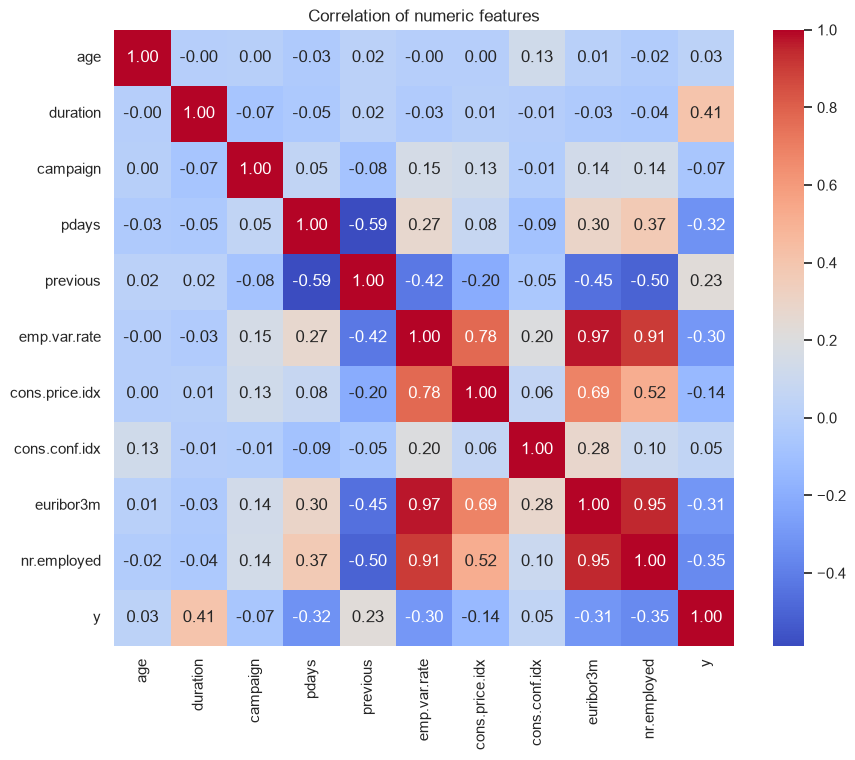

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["age", "duration", "campaign", "euribor3m"]):
    sns.boxplot(x="y", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
corr = df[num_cols].assign(y=(df["y"] == "yes").astype(int)).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of numeric features")
plt.show()

### 1.8 Key findings

**Data quality**
- 41,188 rows × 21 columns, **no null values**, **12 duplicate rows**.
- Missing information is coded as `"unknown"`: `default` (8,597), `education` (1,731), `housing` / `loan` (990), `job` (330), `marital` (80).
- `pdays = 999` means "never contacted before" – this is the case for ~96% of customers.

**Target**
- Highly **imbalanced**: only **11.3%** of customers subscribed (4,640 yes vs 36,548 no).

**Who subscribes**
- **Job:** students (31%) and retired (25%) subscribe most; blue-collar (7%) and services (8%) least.
- **Age:** customers under 25 (24%) and over 60 (46%) convert far more than those aged 25–60 (10%).
- **Previous campaign:** customers whose previous outcome was a **success convert at 65%**, against 9% for customers never contacted before.
- **Default:** customers with `default = unknown` convert at only 5% vs 13% for `no`.
- Education, marital status, housing loan, personal loan and day of week make only small differences.

**How and when they were contacted**
- **Cellular** contact converts at 15% vs **5% for telephone**.
- **May** has the most calls (13,769) but the lowest rate (6%); **Mar, Sep, Oct, Dec** have few calls but rates of 44–50%.
- The more calls in the same campaign, the lower the success: 13% after 1 call, ~9% after 4, under 5% after 8+.

**Numeric relationships**
- `duration` has the strongest correlation with the target (0.41; median 449 s for "yes" vs 164 s for "no"), but it is only known after the call.
- Economic indicators are negatively correlated with subscription (`nr.employed` −0.36, `euribor3m` −0.31, `emp.var.rate` −0.30): customers subscribe more when rates and employment are low.
- These three indicators are **very strongly correlated with each other** (0.91–0.97).

## 2. Task 2 – Predictive Model
### 2.1 Preprocessing

In [12]:
data = df.drop_duplicates().copy()
data = data.drop(columns=["duration"])                    # only known after the call -> leakage
data["contacted_before"] = (data["pdays"] != 999).astype(int)
data = data.drop(columns=["pdays"])                       # 999 is a code, not a real number of days

X = data.drop(columns="y")
y = (data["y"] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (32940, 19)  Test: (8236, 19)


### 2.2 Train and compare four models
All models use the same preprocessing, the same train/test split and `class_weight='balanced'` to handle the imbalance.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}

results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", clone(preprocess)), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3).sort_values("ROC-AUC", ascending=False)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.850,0.399,0.652,0.495,0.815
Random Forest,0.855,0.409,0.638,0.498,0.813
Logistic Regression,0.831,0.360,0.645,0.462,0.800
Decision Tree,0.851,0.399,0.629,0.488,0.798


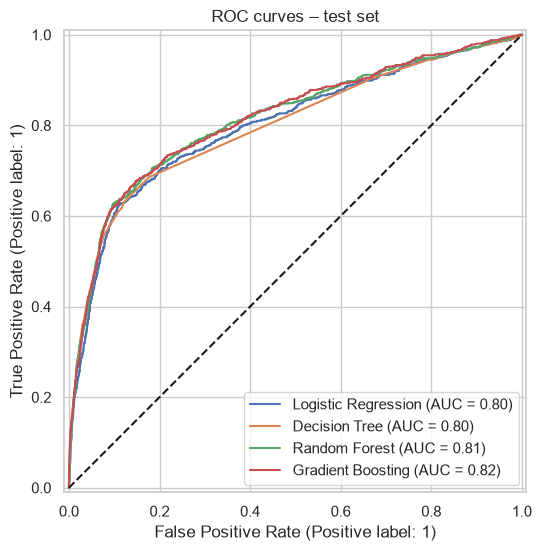

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
plt.title("ROC curves – test set")
plt.show()

### 2.3 Best model – detailed evaluation and feature importance

Best model: Gradient Boosting
              precision    recall  f1-score   support

          no       0.95      0.88      0.91      7308
         yes       0.40      0.65      0.49       928

    accuracy                           0.85      8236
   macro avg       0.68      0.76      0.70      8236
weighted avg       0.89      0.85      0.86      8236



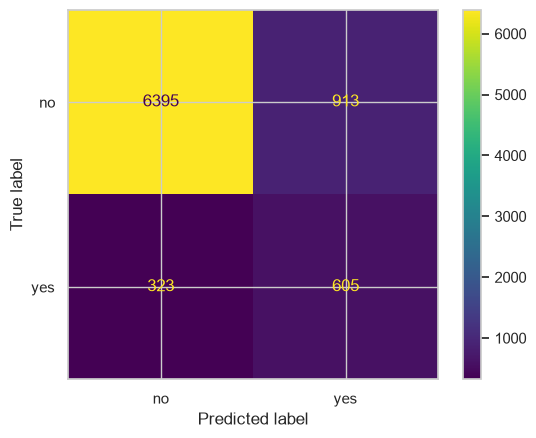

In [15]:
best_name = results_df["ROC-AUC"].idxmax()
best_model = fitted[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no", "yes"])
plt.show()

nr.employed         0.0940
contact             0.0236
euribor3m           0.0165
cons.price.idx      0.0150
cons.conf.idx       0.0143
campaign            0.0058
contacted_before    0.0056
emp.var.rate        0.0046
dtype: float64


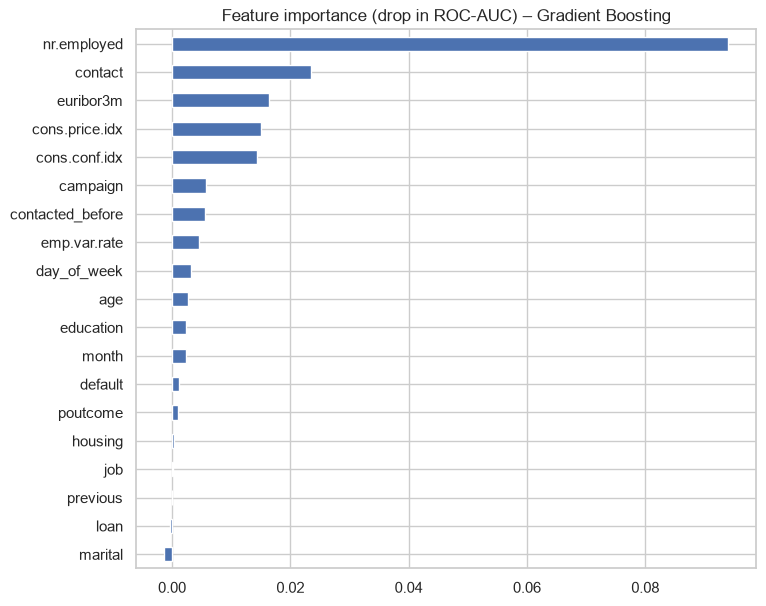

In [16]:
imp = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importances = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
print(importances.sort_values(ascending=False).head(8).round(4))
importances.plot(kind="barh", figsize=(8, 7), title=f"Feature importance (drop in ROC-AUC) – {best_name}")
plt.show()

## 3. Model Comparison Report

Test set: 8,236 customers (928 real buyers). `duration` excluded so the model can be used **before** a call.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Gradient Boosting** | 0.850 | 0.399 | **0.652** | 0.495 | **0.815** |
| Random Forest | 0.855 | 0.409 | 0.638 | **0.498** | 0.813 |
| Logistic Regression | 0.831 | 0.360 | 0.645 | 0.462 | 0.800 |
| Decision Tree | 0.851 | 0.399 | 0.629 | 0.488 | 0.798 |

**How to read it**
- **Accuracy is misleading here** – a model that says "no" to everyone already gets 88.7%. So models are compared on **ROC-AUC** (how well they rank customers from most to least likely to buy) and **Recall / F1** (how many real buyers they catch).
- All four models are close; the ensemble models (Gradient Boosting, Random Forest) are best.

**Recommended model for production: Gradient Boosting (HistGradientBoostingClassifier)**
- Highest ROC-AUC (0.815) and highest recall – it finds **65% of real buyers** (605 of 928).
- Of the customers it flags, ~40% actually buy, vs 11.3% if the bank calls at random – **about 3.5× more efficient**.
- Fast to train and predict, handles the imbalance with `class_weight`, and its probabilities can be used to sort the call list.
- Random Forest is an almost equal alternative; Logistic Regression is the simpler choice if explainability matters more than a small gain in accuracy.
- The most important features for the model are the economic context (`nr.employed`, `euribor3m`, `cons.price.idx`, `cons.conf.idx`), the contact type and whether the customer was contacted before.

## 4. Report on Challenges Faced

| Challenge | Technique used | Reason |
|---|---|---|
| **Imbalanced target** (11.3% yes) | `class_weight="balanced"`, stratified train/test split, evaluated with ROC-AUC / Recall / F1 | Without it the models mostly predict "no" and still look ~89% accurate while missing the buyers |
| **`duration` leaks the outcome** | Dropped the column | It is only known after the call ends, so a real model cannot use it to decide whom to call (as stated in the data description) |
| **`pdays = 999` is a code** ("never contacted") | Replaced `pdays` with a binary flag `contacted_before` | Treating 999 as a number of days would distort the model; ~96% of rows have it |
| **"unknown" values** in 6 categorical columns | Kept "unknown" as its own category | Too many rows to drop (8,597 in `default`), and "unknown" is informative – those customers convert less |
| **Duplicate rows** (12) | Removed with `drop_duplicates()` | Prevents the same row appearing in both train and test |
| **Categorical features** (10 columns) | One-hot encoding | Models need numeric input and these categories have no natural order |
| **Different numeric scales** (e.g. `nr.employed` ~5,000 vs `euribor3m` ~1–5) | `StandardScaler` | Needed for Logistic Regression to work properly |
| **Highly correlated economic indicators** (0.91–0.97) | Kept, but noted | Tree-based models handle correlated features well; it only affects the interpretation of Logistic Regression coefficients |
| **Fair model comparison** | One `Pipeline` per model with the same preprocessing, split and random seed | Ensures differences come from the model, not from the data preparation |

## 5. Task 3 – Suggestions to the Bank Marketing Team

1. **Use the model to rank customers before calling.** Call the customers with the highest predicted probability first – the flagged group converts at ~40% vs 11% for random calling.
2. **Re-contact previous successes first.** Customers whose last campaign was a success subscribe 65% of the time.
3. **Focus on students, retired customers and the over-60 / under-25 age groups** – they convert 2–4× more than average.
4. **Call mobile numbers.** Cellular contact converts at 15% vs 5% for landline.
5. **Limit repeated calls.** Success falls steadily with every extra call; after about 3 calls with no result, move on to a new customer.
6. **Spread the campaign over the year.** May is over-used (1 in 3 calls, 6% success) while March, September, October and December convert at 44–50% with very few calls.
7. **Time campaigns with the economy.** Subscription is much higher when interest rates (euribor) and employment are low, so increase campaign effort in those periods.
8. **Train agents for quality conversations.** Successful calls last much longer (median 7.5 min vs 2.7 min), so engaging the customer matters more than the number of calls.

## 6. Conclusion

- The data is clean (no nulls) but imbalanced (11.3% buyers) and contains a leaking feature (`duration`), which was removed.
- Four models were compared; **Gradient Boosting** is recommended for production (ROC-AUC 0.815, recall 65%).
- Using the model to choose whom to call makes the campaign about **3.5× more efficient** than random calling.
- The biggest drivers of success are the economic context, contact type, previous campaign outcome and customer profile (students, retired, young/old customers).